In [30]:
import requests
import pandas as pd
import time
import os
from datetime import datetime
from dateutil.relativedelta import relativedelta

# 1. Define six cities and time period


cities = {
    "Newcastle": {"latitude": 54.9783, "longitude": -1.6178},
    "Budapest": {"latitude": 47.4979,"longitude": 19.0402},
    "Sydney": {"latitude": -33.8688,"longitude": 151.2093},
    "Cairo": {"latitude": 30.0444,"longitude": 31.2357},
    "Sao Luis": {"latitude": -2.5307,"longitude": -44.3068},
    "Vancouver": {"latitude": 49.2827,"longitude": -123.1207}
}


# Set time period

start_date = "1945-01-01"
end_date = "2024-12-31"


# 2. Create monthly date ranges


def create_monthly_ranges(start_date, end_date):
    start = datetime.strptime(start_date, "%Y-%m-%d")
    end = datetime.strptime(end_date, "%Y-%m-%d")

    ranges = []

    current = start

    while current <= end:
        month_start = current
        month_end = current + relativedelta(months=1) - relativedelta(days=1)

        if month_end > end:
            month_end = end

        ranges.append((
            month_start.strftime("%Y-%m-%d"),
            month_end.strftime("%Y-%m-%d")
        ))

        current = current + relativedelta(months=1)

    return ranges


monthly_ranges = create_monthly_ranges(start_date, end_date)

print("Number of monthly requests:", len(monthly_ranges))
print(monthly_ranges[:3])
print(monthly_ranges[-3:])


# 3. Function to download one month of data


def download_one_month(city_name, latitude, longitude, start_date, end_date):
    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "daily": "temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum",
        "timezone": "auto"
    }

    response = requests.get(url, params=params)

    if response.status_code == 200:
        data = response.json()

        if "daily" in data:
            df = pd.DataFrame(data["daily"])
            df["city"] = city_name
            df["latitude"] = latitude
            df["longitude"] = longitude
            return df

    print(f"Failed: {city_name}, {start_date} to {end_date}")
    print(response.text)
    return None


# 4. Download monthly data with resume function


# Create a folder to store monthly files
output_folder = "monthly_weather_data"
os.makedirs(output_folder, exist_ok=True)

for city_name, location in cities.items():
    print(f"Starting city: {city_name}")

    city_folder_name = city_name.lower().replace(" ", "_")
    city_folder_path = os.path.join(output_folder, city_folder_name)
    os.makedirs(city_folder_path, exist_ok=True)

    for month_start, month_end in monthly_ranges:
        month_code = month_start[:7]  # example: 1945-01

        file_name = f"{city_folder_name}_{month_code}.csv"
        file_path = os.path.join(city_folder_path, file_name)

        # If the file already exists, skip it
        if os.path.exists(file_path):
            print(f"Already exists, skipping: {file_name}")
            continue

        print(f"Downloading {city_name}: {month_start} to {month_end}")

        monthly_df = download_one_month(
            city_name,
            location["latitude"],
            location["longitude"],
            month_start,
            month_end
        )

        if monthly_df is not None:
            monthly_df.to_csv(file_path, index=False)
            print(f"Saved: {file_name}")
        else:
            print(f"Not saved because download failed: {file_name}")

        # Pause to avoid API limit
        time.sleep(1)

    print(f"Finished city: {city_name}")

    # Longer pause between cities
    time.sleep(5)


# 5. Combine all monthly CSV files


all_data = []

for city_name in cities.keys():
    city_folder_name = city_name.lower().replace(" ", "_")
    city_folder_path = os.path.join(output_folder, city_folder_name)

    for file_name in os.listdir(city_folder_path):
        if file_name.endswith(".csv"):
            file_path = os.path.join(city_folder_path, file_name)
            df = pd.read_csv(file_path)
            all_data.append(df)

weather_data = pd.concat(all_data, ignore_index=True)

weather_data.to_csv("six_cities_weather_data.csv", index=False)

print("All monthly files combined successfully.")
print("Final file saved as six_cities_weather_data.csv")

print(weather_data.head())
print(weather_data.info())

print("Cities included:")
print(weather_data["city"].unique())

print("Number of rows by city:")
print(weather_data["city"].value_counts())

Number of monthly requests: 960
[('1945-01-01', '1945-01-31'), ('1945-02-01', '1945-02-28'), ('1945-03-01', '1945-03-31')]
[('2024-10-01', '2024-10-31'), ('2024-11-01', '2024-11-30'), ('2024-12-01', '2024-12-31')]
Starting city: Newcastle
Already exists, skipping: newcastle_1945-01.csv
Already exists, skipping: newcastle_1945-02.csv
Already exists, skipping: newcastle_1945-03.csv
Already exists, skipping: newcastle_1945-04.csv
Already exists, skipping: newcastle_1945-05.csv
Already exists, skipping: newcastle_1945-06.csv
Already exists, skipping: newcastle_1945-07.csv
Already exists, skipping: newcastle_1945-08.csv
Already exists, skipping: newcastle_1945-09.csv
Already exists, skipping: newcastle_1945-10.csv
Already exists, skipping: newcastle_1945-11.csv
Already exists, skipping: newcastle_1945-12.csv
Already exists, skipping: newcastle_1946-01.csv
Already exists, skipping: newcastle_1946-02.csv
Already exists, skipping: newcastle_1946-03.csv
Already exists, skipping: newcastle_1946-

In [31]:
# 6. Data cleaning

# Check column names first
print("Original columns:")
print(weather_data.columns)

# Rename columns for easier use
weather_data = weather_data.rename(columns={
    "time": "time",
    "temperature_2m_mean (°C)": "temperature",
    "temperature_2m_mean": "temperature",
    "relative_humidity_2m_mean (%)": "humidity",
    "relative_humidity_2m_mean": "humidity",
    "precipitation_sum (mm)": "precipitation",
    "precipitation_sum": "precipitation"
})

# Convert time column to datetime format
weather_data["time"] = pd.to_datetime(weather_data["time"])

# Check missing values
print("Missing values before cleaning:")
print(weather_data.isnull().sum())

# Remove rows with missing values in key weather variables
weather_data = weather_data.dropna(subset=[
    "temperature",
    "humidity",
    "precipitation"
])

# Create year and decade columns
weather_data["year"] = weather_data["time"].dt.year
weather_data["decade"] = (weather_data["year"] // 10) * 10

# Check the cleaned data
print(weather_data.head())
print(weather_data.info())

# Save cleaned data
weather_data.to_csv("six_cities_weather_data_cleaned.csv", index=False)

print("Data cleaning completed successfully.")
print("Cleaned CSV file saved as six_cities_weather_data_cleaned.csv")

Original columns:
Index(['time', 'temperature_2m_mean', 'relative_humidity_2m_mean',
       'precipitation_sum', 'city', 'latitude', 'longitude'],
      dtype='object')
Missing values before cleaning:
time             0
temperature      0
humidity         0
precipitation    0
city             0
latitude         0
longitude        0
dtype: int64
        time  temperature  humidity  precipitation       city  latitude  \
0 1976-04-01          4.7        70            1.0  Newcastle   54.9783   
1 1976-04-02          2.9        87            8.4  Newcastle   54.9783   
2 1976-04-03          4.2        78            0.2  Newcastle   54.9783   
3 1976-04-04          6.1        75            0.4  Newcastle   54.9783   
4 1976-04-05          8.2        77            0.0  Newcastle   54.9783   

   longitude  year  decade  
0    -1.6178  1976    1970  
1    -1.6178  1976    1970  
2    -1.6178  1976    1970  
3    -1.6178  1976    1970  
4    -1.6178  1976    1970  
<class 'pandas.core.frame.Da

In [32]:
# 7. Summary statistics by year

annual_stats = weather_data.groupby(["city", "year"]).agg(
    average_temperature=("temperature", "mean"),
    average_humidity=("humidity", "mean"),
    total_precipitation=("precipitation", "sum")
).reset_index()

# Preview annual statistics
print(annual_stats.head())
print(annual_stats.info())

# Save annual statistics
annual_stats.to_csv("six_cities_annual_statistics.csv", index=False)

print("Annual summary statistics completed successfully.")
print("CSV file saved as: six_cities_annual_statistics.csv")

       city  year  average_temperature  average_humidity  total_precipitation
0  Budapest  1945            10.317808         72.794521                534.9
1  Budapest  1946            11.703562         63.345205                351.7
2  Budapest  1947            10.946575         67.920548                448.8
3  Budapest  1948            10.466940         71.054645                525.6
4  Budapest  1949            11.300000         68.454795                505.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   city                 480 non-null    object 
 1   year                 480 non-null    int32  
 2   average_temperature  480 non-null    float64
 3   average_humidity     480 non-null    float64
 4   total_precipitation  480 non-null    float64
dtypes: float64(3), int32(1), object(1)
memory usage: 17.0+ KB
None
Annual sum

In [33]:
# 8. Summary statistics by decade

decade_stats = weather_data.groupby(["city", "decade"]).agg(
    average_temperature=("temperature", "mean"),
    average_humidity=("humidity", "mean"),
    total_precipitation=("precipitation", "sum")
).reset_index()

# Calculate average annual precipitation in each decade
decade_stats["average_annual_precipitation"] = (
    decade_stats["total_precipitation"] / 10
)

# Preview decade statistics
print(decade_stats.head())
print(decade_stats.info())

# Save decade statistics
decade_stats.to_csv("six_cities_decade_statistics.csv", index=False)

print("Decade summary statistics completed successfully.")
print("CSV file saved as: six_cities_decade_statistics.csv")


       city  decade  average_temperature  average_humidity  \
0  Budapest    1940            10.946714         68.715225   
1  Budapest    1950            10.689896         71.311884   
2  Budapest    1960            10.313934         74.183958   
3  Budapest    1970            10.309392         75.669496   
4  Budapest    1980            10.331508         74.578702   

   total_precipitation  average_annual_precipitation  
0               2366.0                        236.60  
1               5474.3                        547.43  
2               6490.2                        649.02  
3               6645.9                        664.59  
4               5862.6                        586.26  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   city                          54 non-null     object 
 1   decade       

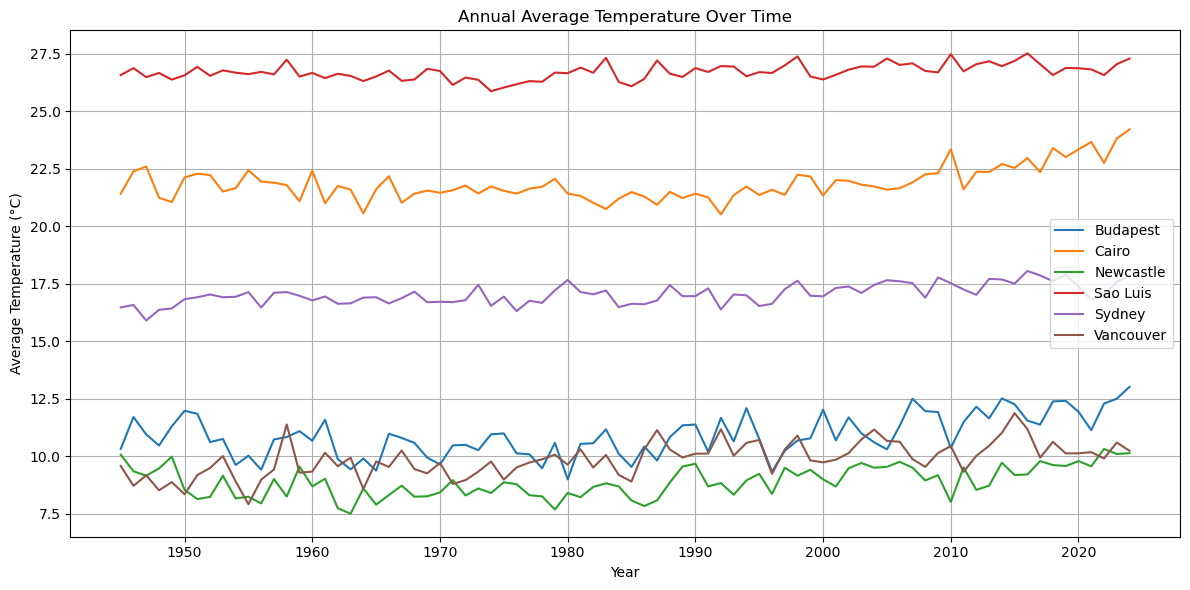

In [34]:
# 9. Visualization: Temperature trend over time

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for city in annual_stats["city"].unique():
    city_data = annual_stats[annual_stats["city"] == city]
    plt.plot(
        city_data["year"],
        city_data["average_temperature"],
        label=city
    )

plt.title("Annual Average Temperature Over Time")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

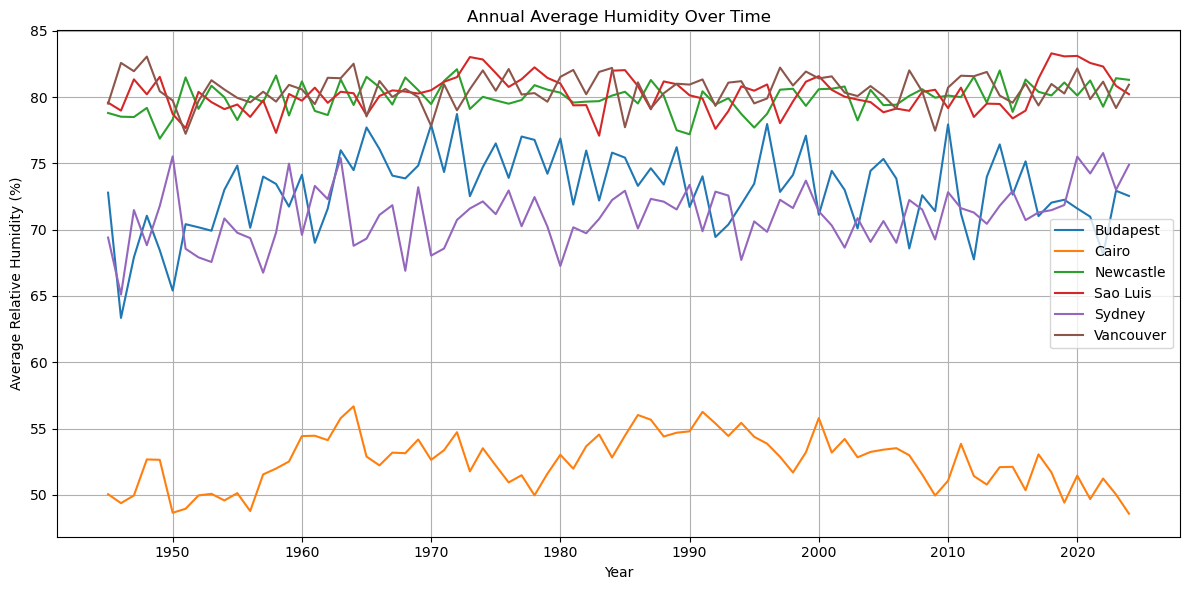

In [35]:
# 10. Visualization: Humidity trend over time

plt.figure(figsize=(12, 6))

for city in annual_stats["city"].unique():
    city_data = annual_stats[annual_stats["city"] == city]
    plt.plot(
        city_data["year"],
        city_data["average_humidity"],
        label=city
    )

plt.title("Annual Average Humidity Over Time")
plt.xlabel("Year")
plt.ylabel("Average Relative Humidity (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

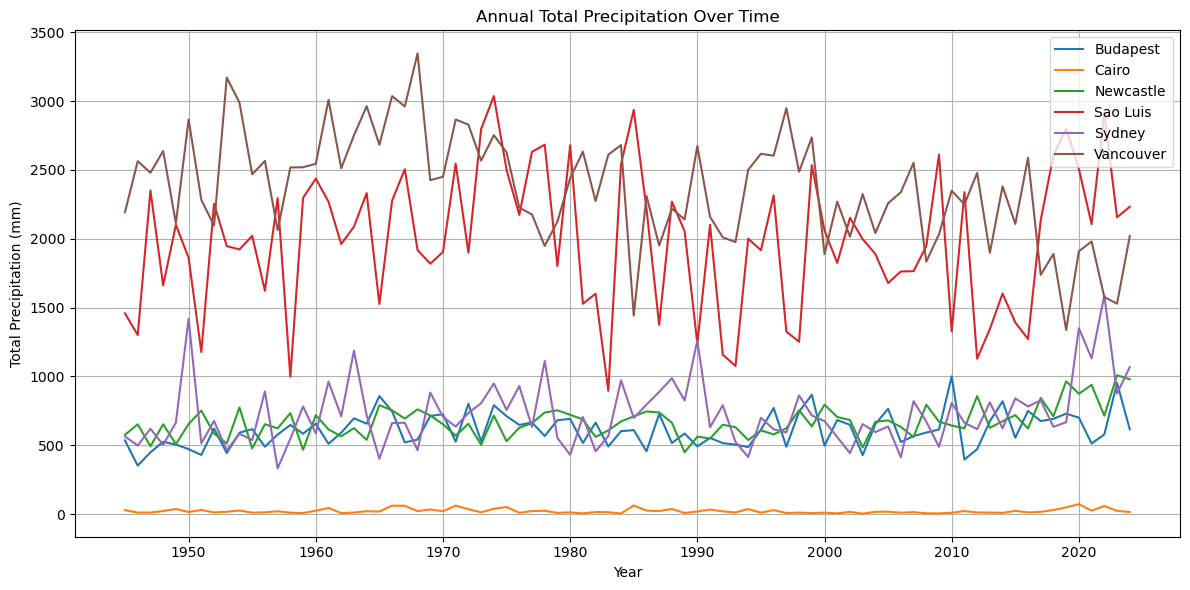

In [36]:
# 11. Visualization: Precipitation trend over time


plt.figure(figsize=(12, 6))

for city in annual_stats["city"].unique():
    city_data = annual_stats[annual_stats["city"] == city]
    plt.plot(
        city_data["year"],
        city_data["total_precipitation"],
        label=city
    )

plt.title("Annual Total Precipitation Over Time")
plt.xlabel("Year")
plt.ylabel("Total Precipitation (mm)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

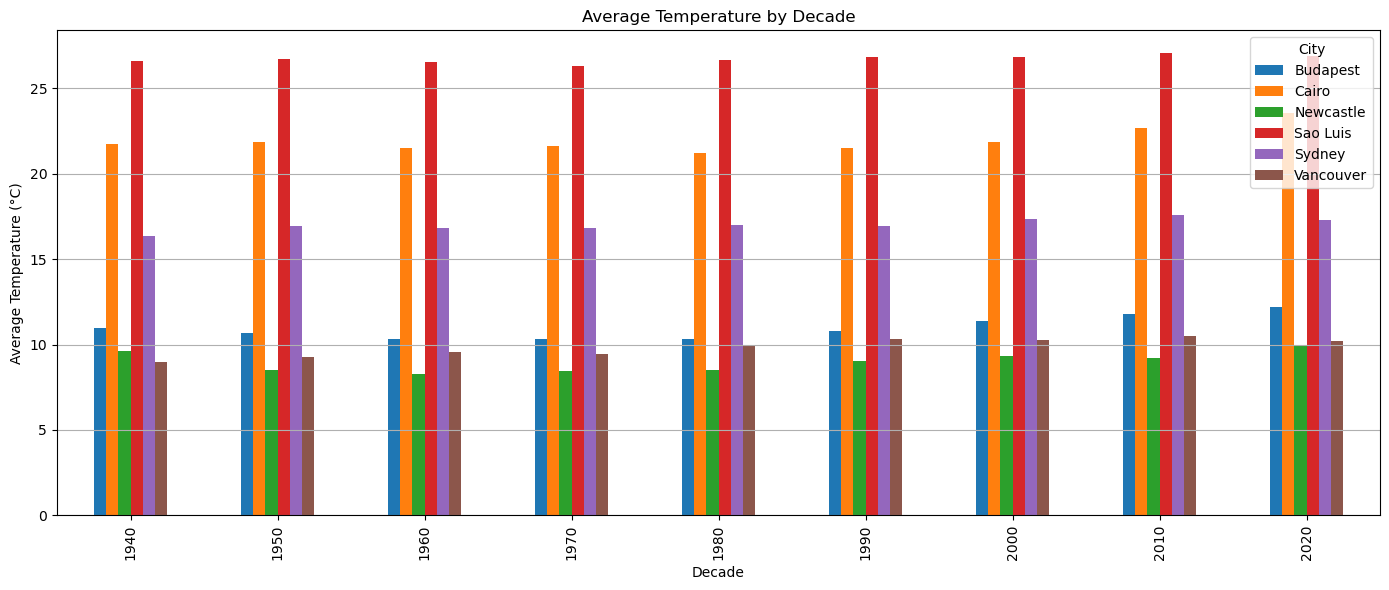

In [37]:
# 12. Visualization: Average temperature by decade


temperature_pivot = decade_stats.pivot(
    index="decade",
    columns="city",
    values="average_temperature"
)

temperature_pivot.plot(kind="bar", figsize=(14, 6))

plt.title("Average Temperature by Decade")
plt.xlabel("Decade")
plt.ylabel("Average Temperature (°C)")
plt.legend(title="City")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

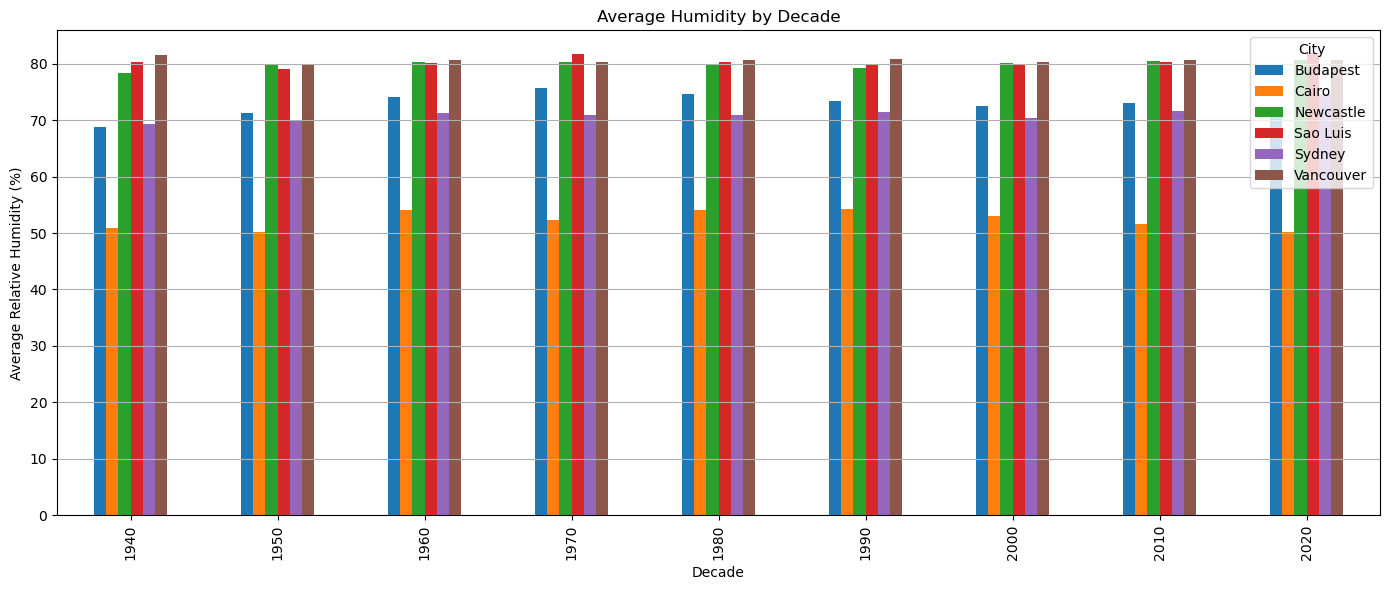

In [38]:
# 13. Visualization: Average humidity by decade


humidity_pivot = decade_stats.pivot(
    index="decade",
    columns="city",
    values="average_humidity"
)

humidity_pivot.plot(kind="bar", figsize=(14, 6))

plt.title("Average Humidity by Decade")
plt.xlabel("Decade")
plt.ylabel("Average Relative Humidity (%)")
plt.legend(title="City")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

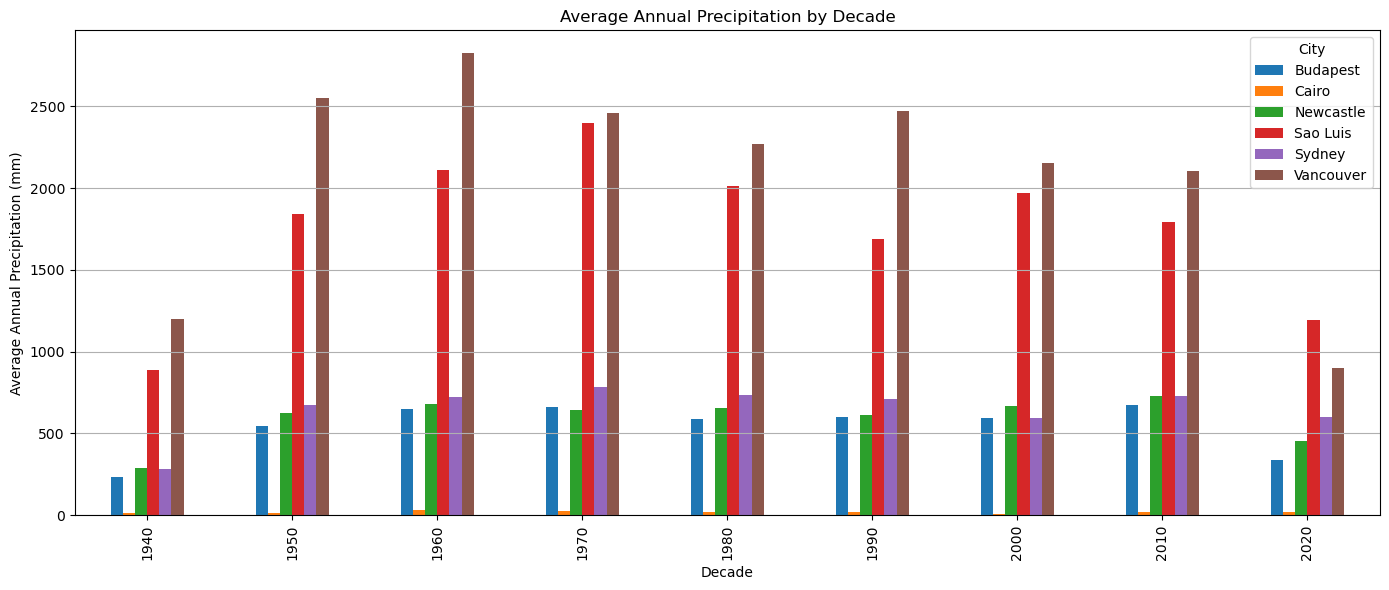

In [39]:
# 14. Visualization: Average annual precipitation by decade


precipitation_pivot = decade_stats.pivot(
    index="decade",
    columns="city",
    values="average_annual_precipitation"
)

precipitation_pivot.plot(kind="bar", figsize=(14, 6))

plt.title("Average Annual Precipitation by Decade")
plt.xlabel("Decade")
plt.ylabel("Average Annual Precipitation (mm)")
plt.legend(title="City")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [40]:
# 15. Prepare data for maps


import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Select the latest 10 years
latest_10_years = annual_stats[
    annual_stats["year"] >= annual_stats["year"].max() - 9
]

# Create location dataframe
city_locations = pd.DataFrame([
    {"city": "Newcastle", "latitude": 54.9783, "longitude": -1.6178},
    {"city": "Budapest", "latitude": 47.4979, "longitude": 19.0402},
    {"city": "Sydney", "latitude": -33.8688, "longitude": 151.2093},
    {"city": "Cairo", "latitude": 30.0444, "longitude": 31.2357},
    {"city": "Sao Luis", "latitude": -2.5307, "longitude": -44.3068},
    {"city": "Vancouver", "latitude": 49.2827, "longitude": -123.1207}
])

# Calculate recent average weather values
recent_map_data = latest_10_years.groupby("city").agg(
    recent_average_temperature=("average_temperature", "mean"),
    recent_average_humidity=("average_humidity", "mean"),
    recent_average_precipitation=("total_precipitation", "mean")
).reset_index()

# Add latitude and longitude
recent_map_data = recent_map_data.merge(city_locations, on="city")

print(recent_map_data)


        city  recent_average_temperature  recent_average_humidity  \
0   Budapest                   12.084520                71.934163   
1      Cairo                   23.198195                50.753327   
2  Newcastle                    9.727060                80.527188   
3   Sao Luis                   26.972944                81.426213   
4     Sydney                   17.551600                73.174484   
5  Vancouver                   10.478207                80.456675   

   recent_average_precipitation  latitude  longitude  
0                        676.37   47.4979    19.0402  
1                         32.52   30.0444    31.2357  
2                        837.48   54.9783    -1.6178  
3                       2212.64   -2.5307   -44.3068  
4                        976.38  -33.8688   151.2093  
5                       1867.76   49.2827  -123.1207  


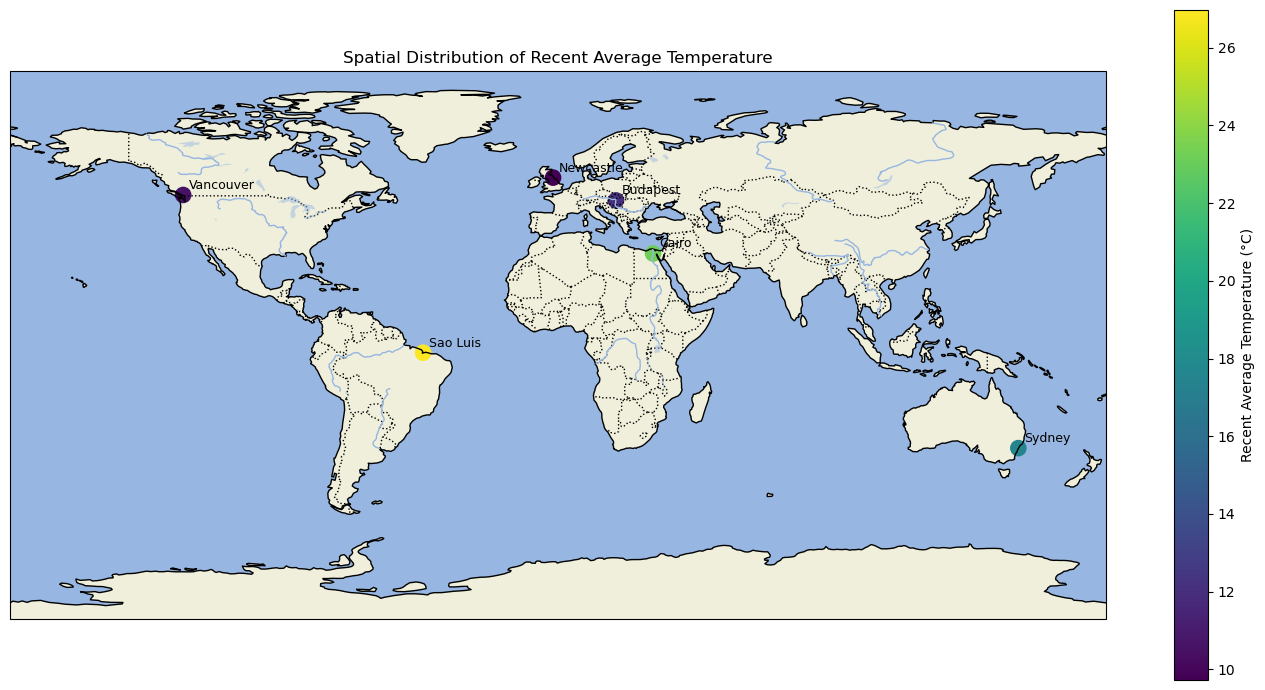

In [41]:
# 16. Map: Recent average temperature


plt.figure(figsize=(14, 7))

ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_global()

ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAKES, alpha=0.5)
ax.add_feature(cfeature.RIVERS)

scatter = ax.scatter(
    recent_map_data["longitude"],
    recent_map_data["latitude"],
    c=recent_map_data["recent_average_temperature"],
    s=120,
    transform=ccrs.PlateCarree()
)

for _, row in recent_map_data.iterrows():
    ax.text(
        row["longitude"] + 2,
        row["latitude"] + 2,
        row["city"],
        transform=ccrs.PlateCarree(),
        fontsize=9
    )

plt.colorbar(scatter, label="Recent Average Temperature (°C)")
plt.title("Spatial Distribution of Recent Average Temperature")
plt.tight_layout()
plt.show()

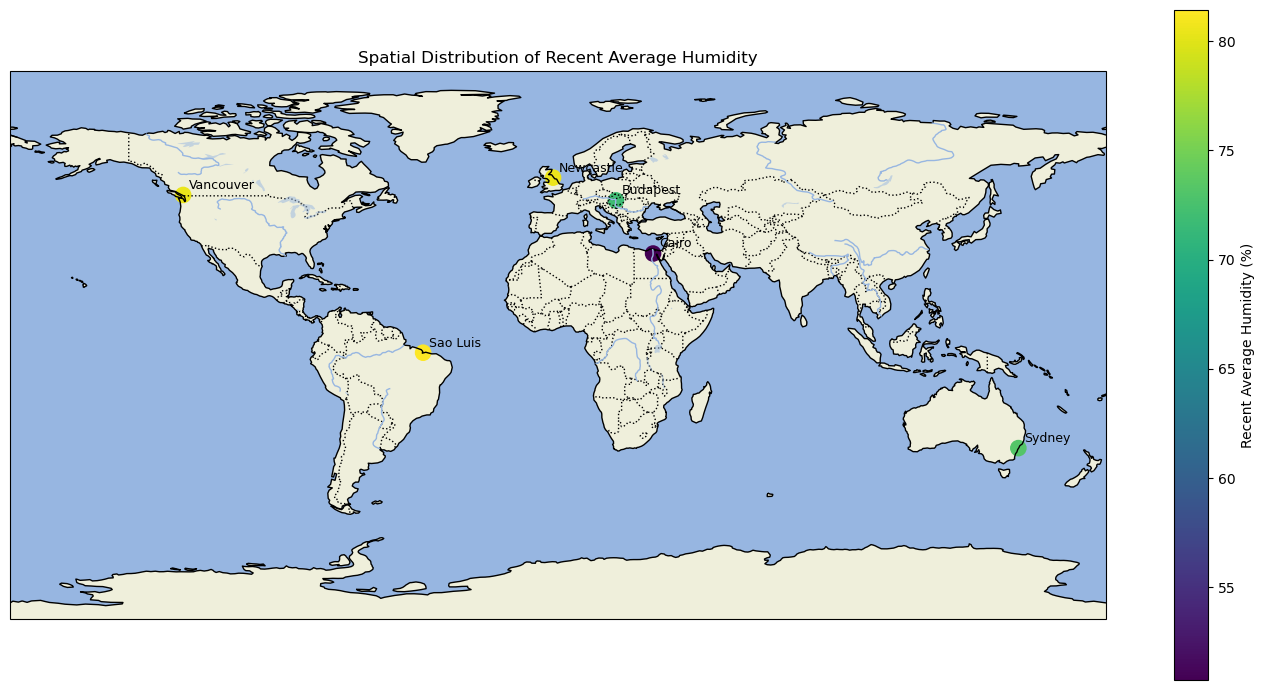

In [42]:
# 17. Map: Recent average humidity


plt.figure(figsize=(14, 7))

ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_global()

ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAKES, alpha=0.5)
ax.add_feature(cfeature.RIVERS)

scatter = ax.scatter(
    recent_map_data["longitude"],
    recent_map_data["latitude"],
    c=recent_map_data["recent_average_humidity"],
    s=120,
    transform=ccrs.PlateCarree()
)

for _, row in recent_map_data.iterrows():
    ax.text(
        row["longitude"] + 2,
        row["latitude"] + 2,
        row["city"],
        transform=ccrs.PlateCarree(),
        fontsize=9
    )

plt.colorbar(scatter, label="Recent Average Humidity (%)")
plt.title("Spatial Distribution of Recent Average Humidity")
plt.tight_layout()
plt.show()

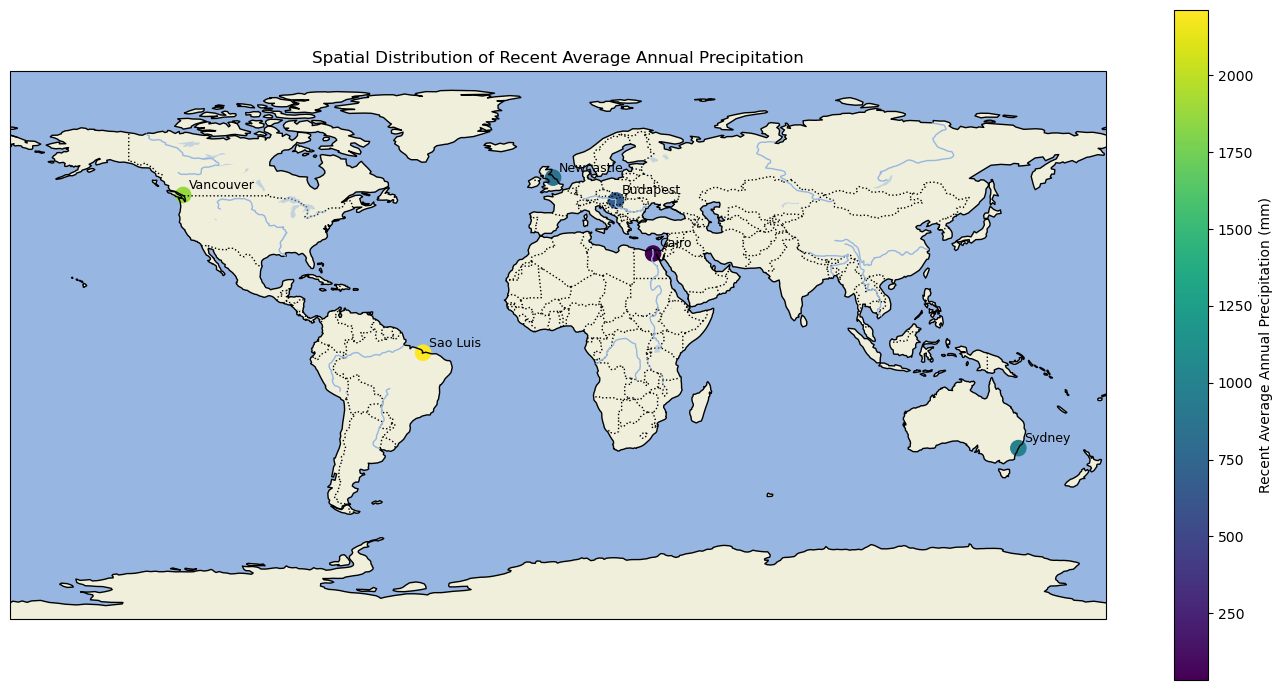

In [43]:
# 18. Map: Recent average precipitation


plt.figure(figsize=(14, 7))

ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_global()

ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAKES, alpha=0.5)
ax.add_feature(cfeature.RIVERS)

scatter = ax.scatter(
    recent_map_data["longitude"],
    recent_map_data["latitude"],
    c=recent_map_data["recent_average_precipitation"],
    s=120,
    transform=ccrs.PlateCarree()
)

for _, row in recent_map_data.iterrows():
    ax.text(
        row["longitude"] + 2,
        row["latitude"] + 2,
        row["city"],
        transform=ccrs.PlateCarree(),
        fontsize=9
    )

plt.colorbar(scatter, label="Recent Average Annual Precipitation (mm)")
plt.title("Spatial Distribution of Recent Average Annual Precipitation")
plt.tight_layout()
plt.show()

In [44]:
# 19. Change analysis: first 10 years vs latest 10 years

# Find the first year and last year in the dataset
first_year = annual_stats["year"].min()
last_year = annual_stats["year"].max()

print("First year:", first_year)
print("Last year:", last_year)

# Select first 10 years
first_10_years = annual_stats[
    annual_stats["year"] <= first_year + 9
]

# Select latest 10 years
latest_10_years = annual_stats[
    annual_stats["year"] >= last_year - 9
]

# Calculate average values for the first 10 years
first_10_summary = first_10_years.groupby("city").agg(
    first_10_average_temperature=("average_temperature", "mean"),
    first_10_average_humidity=("average_humidity", "mean"),
    first_10_average_precipitation=("total_precipitation", "mean")
).reset_index()

# Calculate average values for the latest 10 years
latest_10_summary = latest_10_years.groupby("city").agg(
    latest_10_average_temperature=("average_temperature", "mean"),
    latest_10_average_humidity=("average_humidity", "mean"),
    latest_10_average_precipitation=("total_precipitation", "mean")
).reset_index()

# Merge two summaries
change_summary = first_10_summary.merge(
    latest_10_summary,
    on="city"
)

# Calculate changes
change_summary["temperature_change"] = (
    change_summary["latest_10_average_temperature"] -
    change_summary["first_10_average_temperature"]
)

change_summary["humidity_change"] = (
    change_summary["latest_10_average_humidity"] -
    change_summary["first_10_average_humidity"]
)

change_summary["precipitation_change"] = (
    change_summary["latest_10_average_precipitation"] -
    change_summary["first_10_average_precipitation"]
)

# Show result
print(change_summary)

# Save result
change_summary.to_csv("six_cities_change_summary.csv", index=False)

print("Change analysis completed successfully.")
print("CSV file saved as: six_cities_change_summary.csv")

First year: 1945
Last year: 2024
        city  first_10_average_temperature  first_10_average_humidity  \
0   Budapest                     10.954251                  69.250621   
1      Cairo                     21.842480                  50.183940   
2  Newcastle                      9.025040                  79.168135   
3   Sao Luis                     26.638167                  79.718736   
4     Sydney                     16.633508                  69.703632   
5  Vancouver                      9.079805                  80.612937   

   first_10_average_precipitation  latest_10_average_temperature  \
0                          492.40                      12.084520   
1                           20.99                      23.198195   
2                          616.18                       9.727060   
3                         1803.76                      26.972944   
4                          650.72                      17.551600   
5                         2539.48              

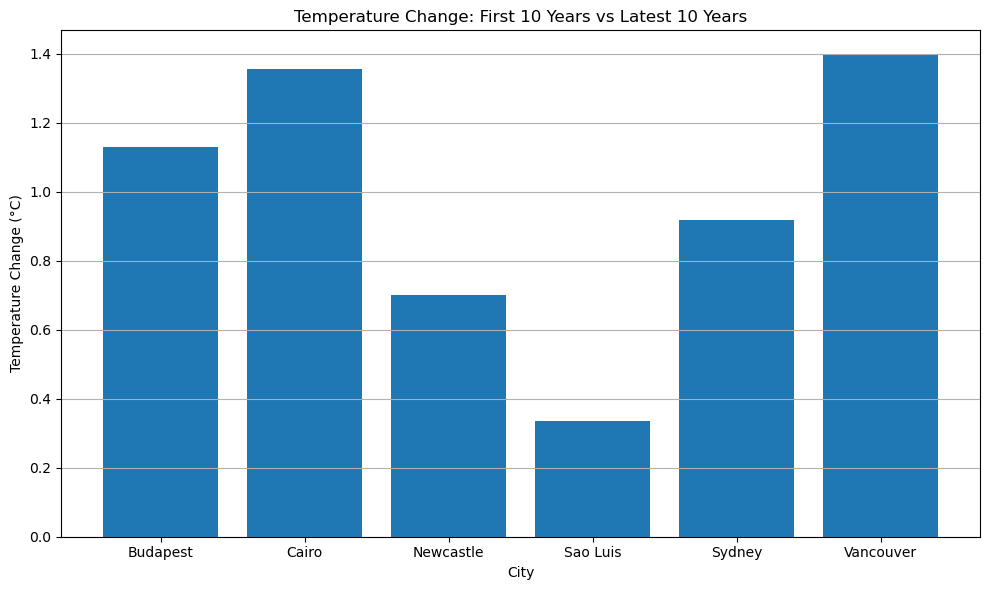

In [45]:

# 20. Visualization: Temperature change


plt.figure(figsize=(10, 6))

plt.bar(
    change_summary["city"],
    change_summary["temperature_change"]
)

plt.title("Temperature Change: First 10 Years vs Latest 10 Years")
plt.xlabel("City")
plt.ylabel("Temperature Change (°C)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

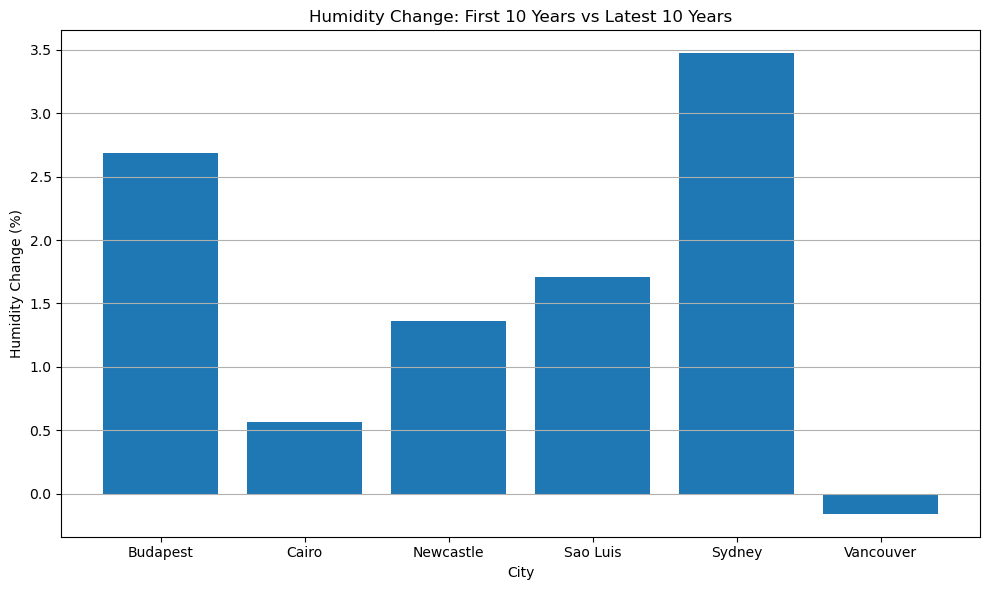

In [46]:
# 21. Visualization: Humidity change

plt.figure(figsize=(10, 6))

plt.bar(
    change_summary["city"],
    change_summary["humidity_change"]
)

plt.title("Humidity Change: First 10 Years vs Latest 10 Years")
plt.xlabel("City")
plt.ylabel("Humidity Change (%)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()



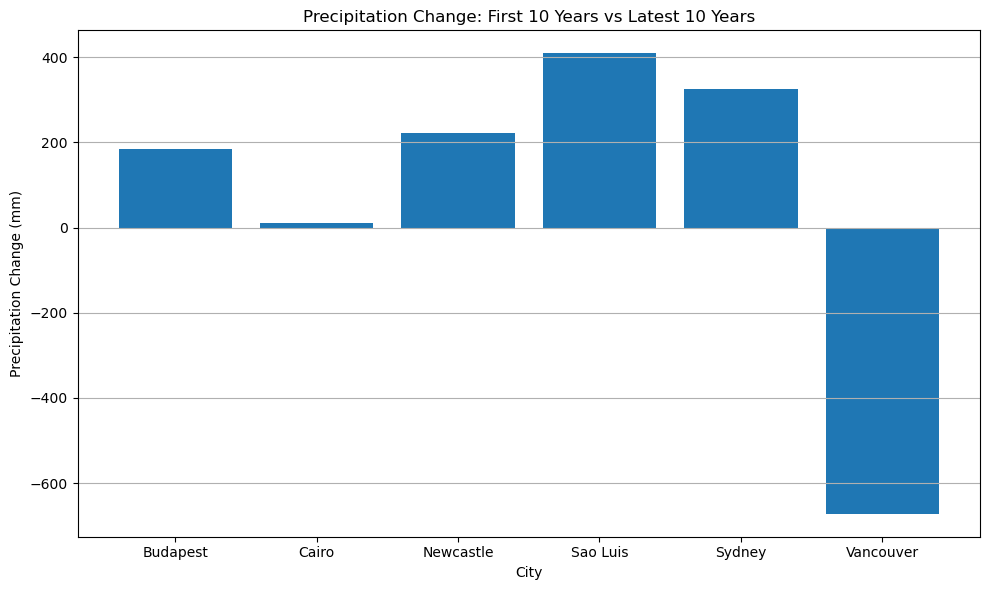

In [47]:
# 22. Visualization: Precipitation change

plt.figure(figsize=(10, 6))

plt.bar(
    change_summary["city"],
    change_summary["precipitation_change"]
)

plt.title("Precipitation Change: First 10 Years vs Latest 10 Years")
plt.xlabel("City")
plt.ylabel("Precipitation Change (mm)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()